In [40]:
# 그래프 관련
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np

# 머신러닝 관련
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier  #평균절대값오차
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error

In [41]:
# 농어 길이, 무게

perch_length = np.array(
    [8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0,
    21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5,
    22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5,
    27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0,
    36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0,
    40.0, 42.0, 43.0, 43.0, 43.5, 44.0]
    )
perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0]
    )

In [42]:
data = np.column_stack((perch_length, perch_weight))
data[:2]

array([[ 8.4,  5.9],
       [13.7, 32. ]])

In [43]:
# 훈련 데이터 / 테스트 데이터 분리
train_data,test_data,train_label,test_label = \
    train_test_split(perch_length,perch_weight)
# test_data

In [44]:
# 훈련 데이터는 2차원 데이터가 돼야 함
train_data = train_data.reshape(-1,1)
test_data = test_data.reshape(-1,1)
#train_data[:2]
#test_data[:2]

In [45]:
lr = LinearRegression()
lr.fit(train_data, train_label)
predict = lr.predict(test_data)
print('무게예측: ', predict)
score = lr.score(train_data, train_label)
score2 = lr.score(test_data, test_label)
print(f'정확도:{score*100}%, {score2*100}%')

무게예측:  [223.33744756 752.71980855 923.48831209 786.87350926 359.9522504
  90.1380148  295.06021905 616.10500571 684.41240713 325.79854969
 172.1068965  786.87350926 172.1068965  889.33461138]
정확도:91.20029149064082%, 89.56759692391209%


In [46]:
result = lr.predict([[27]])
print(result)

[342.87540004]


In [47]:
# 1차원
i_data = input('생선의 길이 입력(예: 27(cm))')
i_data = float(i_data)
predict = lr.predict([[i_data]])
print('무게예측: ', predict)

무게예측:  [445.33650217]


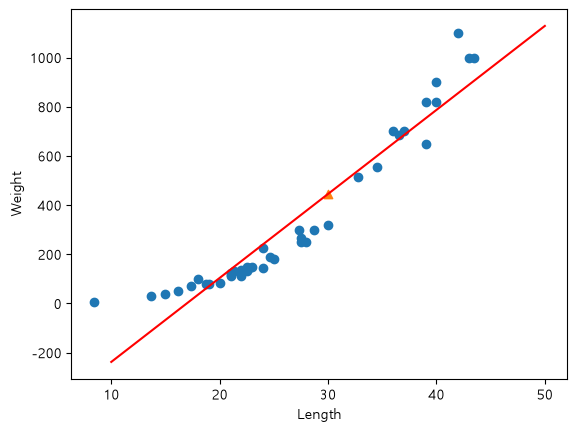

In [49]:
plt.scatter(train_data,train_label)
plt.scatter(i_data,predict, marker='^')
plt.plot([10,50],[10*lr.coef_+lr.intercept_,50*lr.coef_+lr.intercept_], color='red')
plt.xlabel('Length')
plt.ylabel('Weight')
plt.show()